# 3.2 — Detección de anomalías / outliers

**Aspecto del rúbrica:** *Anomalías (outliers), usando al menos dos técnicas*.

Un *outlier* (valor atípico) es un periodo que se sale de lo común. Puede ser
un **error de medición**, que conviene revisar, o un **evento real**, como una
ola de calor, un episodio de contaminación o un brote de casos, que conviene
conservar porque es justo lo que se quiere estudiar. Esta libreta busca esos
periodos con tres técnicas distintas y decide qué hacer con cada uno.

Responde tres preguntas:

1. ¿Hay valores que se salen de lo normal en cada variable?
2. ¿Hay semanas raras por la **combinación** de varias variables, aunque cada
   una por separado parezca normal?
3. Lo que sale raro, ¿es un error o un evento real?

## Resumen

- **Casi no hay valores extremos sueltos.** Las reglas clásicas solo marcan 3
  de 313 semanas: dos con el ozono muy bajo (diciembre de 2016) y la del PM10
  más alto (noviembre de 2017).
- **Comparando cada semana con lo normal para su mes aparecen más**, sobre todo
  las semanas de 2020 con muchos menos casos por la pandemia.
- **Isolation Forest y LOF coinciden en 7 semanas raras.** La mayoría son
  eventos reales (un episodio de contaminación, una primavera muy seca, una
  semana de lluvias) o semanas de 2020. Solo el ozono muy bajo de diciembre de
  2016 parece un posible error del sensor.
- **No se borra ni se corrige ningún dato.** Se guardan marcas para poder
  repetir los análisis sin esas semanas y ver si los resultados cambian.

## Técnicas que se usan

1. **Reglas clásicas (IQR y Z-score):** revisan una variable a la vez y marcan
   los valores que quedan muy lejos de la mayoría. Como en Hermosillo cada
   variable cambia mucho con la época del año, se agrega una versión que
   compara cada semana **con lo normal para su mes**.
2. **Isolation Forest:** busca semanas con una combinación rara de valores. La
   idea: si se separan las semanas con cortes al azar, una semana rara queda
   sola con muy pocos cortes.
3. **Local Outlier Factor (LOF):** compara cada semana con las semanas que más
   se le parecen; si queda lejos de todas ellas ("sola"), es rara.

## Entradas

| Ruta | Contenido |
|------|-----------|
| `data/processed/panel_eda_imputado_semanal.parquet` o `_mensual` (según `GRANULARIDAD`) | Panel sin huecos (salida de `3.1-datos-faltantes.ipynb`). Se usa este porque Isolation Forest y LOF no aceptan valores vacíos |
| `data/processed/panel_eda_semanal.parquet` o `panel_eda.parquet` | Panel antes de rellenar huecos (paso 7 de `3.0`); solo sirve para saber qué valores rellenó 3.1 |

## Salidas

- Figuras en `reports/figures/` (`outliers_*_{GRANULARIDAD}.png`).
- Tabla que compara lo que encuentra cada técnica.
- `data/processed/panel_eda_outliers_{GRANULARIDAD}.parquet`: el panel con una
  marca por técnica, para poder repetir análisis sin las semanas raras.
- Qué periodos se conservan (eventos reales) y cuáles se revisan.

## Configuración e imports

In [1]:
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().parent.parent  # notebooks/<seccion>/ -> raiz del proyecto
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

from sonora_health_climate_eda.config import FIGURES_DIR, PROCESSED_DATA_DIR

GRANULARIDAD = "semanal"  # "mensual" para la comparación

_CFG = {
    "semanal": {"archivo": "panel_eda_semanal.parquet", "fecha": "fecha_semana",
                "y": "casos_ira_total", "tmax": "tmax_media_sem",
                "ola_p95_y_sequia": "semana_ola_calor_p95_y_sequia"},
    "mensual": {"archivo": "panel_eda.parquet", "fecha": "fecha_mes",
                "y": "casos_ira_por_semana", "tmax": "tmax_media_mes",
                "ola_p95_y_sequia": "mes_ola_calor_p95_y_sequia"},
}[GRANULARIDAD]
FECHA, Y, TMAX = _CFG["fecha"], _CFG["y"], _CFG["tmax"]
PERIODOS = "semanas" if GRANULARIDAD == "semanal" else "meses"
RARAS = "raras" if GRANULARIDAD == "semanal" else "raros"  # semanas raras / meses raros

# Quedan fuera de las reglas de una variable:
#   - dias_ola_calor_p95: casi siempre 0; cualquier semana con ola saldría "rara".
#   - severidad_sequia: escala 0-4, no medición continua (solo entra a IF/LOF).
#   - IM: rampa interpolada entre censos (ver 3.0).
VARS_CONTINUAS = [Y, TMAX, "humedad_rel_media", "pm10_ugm3", "o3_max8h_ppb"]
VARS_MULTI = VARS_CONTINUAS + ["severidad_sequia"]

NOMBRE = {
    Y: "Casos de IRA",
    TMAX: "Temperatura máx. (°C)",
    "humedad_rel_media": "Humedad (%)",
    "pm10_ugm3": "PM10 (µg/m³)",
    "o3_max8h_ppb": "Ozono (ppb)",
    "severidad_sequia": "Sequía (0 a 4)",
}
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

# ambas técnicas marcan el mismo 5 % más raro (16 de 313 semanas) para compararlas
CONTAMINACION = 0.05
SEMILLA = 42

AZUL, AZUL_CLARO, NARANJA, AQUA = "#2a78d6", "#9ec5f4", "#eb6834", "#1baf7a"
GRIS, GRIS_CLARO, FONDO_2020 = "#52514e", "#b4b2a9", "#f0efec"
AZULES = LinearSegmentedColormap.from_list(
    "azules", ["#eef4fc", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True})

# panel: ya rellenado por 3.1 (IF y LOF no aceptan vacíos).
# panel_original + tabla 'imputado': qué valores estimó 3.1 (un estimado no es un evento real).
ruta_imputado = PROCESSED_DATA_DIR / f"panel_eda_imputado_{GRANULARIDAD}.parquet"
ruta_original = PROCESSED_DATA_DIR / _CFG["archivo"]
if not ruta_imputado.exists():
    raise FileNotFoundError(
        f"Falta {ruta_imputado.name}: correr 3.1-datos-faltantes.ipynb con GRANULARIDAD = '{GRANULARIDAD}'"
    )
if not ruta_original.exists():
    raise FileNotFoundError(f"Falta {ruta_original.name}: completar el paso 7 de 3.0-integracion-espacial.ipynb")

panel = pd.read_parquet(ruta_imputado).sort_values(FECHA).reset_index(drop=True)
panel_original = pd.read_parquet(ruta_original)

imputado = (
    panel_original.set_index(FECHA)[VARS_MULTI]
    .isna()
    .reindex(panel[FECHA])
    .reset_index(drop=True)
)

print(f"Panel {GRANULARIDAD}: {len(panel)} {PERIODOS}, "
      f"de {panel[FECHA].min():%Y-%m-%d} a {panel[FECHA].max():%Y-%m-%d}")
print("Valores rellenados por 3.1:",
      {NOMBRE[c]: int(n) for c, n in imputado.sum().items() if n > 0})


Panel semanal: 313 semanas, de 2015-01-04 a 2020-12-27
Valores rellenados por 3.1: {'PM10 (µg/m³)': 27, 'Ozono (ppb)': 34, 'Sequía (0 a 4)': 1}


In [2]:
(panel[VARS_MULTI].describe().T[["mean", "min", "50%", "max"]]
 .rename(index=NOMBRE, columns={"mean": "promedio", "min": "mínimo", "50%": "mediana",
                                "max": "máximo"})
 .round(1))


,promedio,mínimo,mediana,máximo
Casos de IRA,3607.3,569.0,3602.0,8148.0
Temperatura máx. (°C),31.8,17.9,32.5,41.8
Humedad (%),44.4,18.9,42.7,81.1
PM10 (µg/m³),39.3,11.1,39.8,84.4
Ozono (ppb),35.9,7.6,35.8,59.2
Sequía (0 a 4),0.9,0.0,1.0,4.0


## Técnica 1 — Reglas clásicas (una variable a la vez)

- **IQR (rango intercuartílico):** se toma el rango donde cae la mitad central
  de los datos y se estira 1.5 veces hacia arriba y hacia abajo. Lo que queda
  fuera es atípico. Es la misma regla que dibuja los puntos sueltos de un
  boxplot.
- **Z-score:** mide qué tan lejos está un valor del promedio, en "pasos" del
  tamaño de la variación típica (la desviación estándar). Más de 3 pasos se
  considera atípico: en datos comunes pasa menos de 3 veces de cada 1,000.

In [3]:
def outliers_iqr(s: pd.Series, k: float = 1.5) -> pd.Series:
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)


def outliers_zscore(s: pd.Series, threshold: float = 3.0) -> pd.Series:
    z = (s - s.mean()) / s.std()
    return z.abs() > threshold


def listar_marcados(marcas: pd.DataFrame, tecnica: str) -> pd.DataFrame:
    """Una fila por cada valor marcado: fecha, variable, valor y si lo rellenó 3.1."""
    pares = marcas.stack()
    pares = pares[pares].index
    return pd.DataFrame({
        "técnica": tecnica,
        "fecha": panel.loc[pares.get_level_values(0), FECHA].dt.date.to_numpy(),
        "variable": [NOMBRE[v] for v in pares.get_level_values(1)],
        "valor": [round(panel.at[i, v], 2) for i, v in pares],
        "rellenado en 3.1": ["sí" if imputado.at[i, v] else "no" for i, v in pares],
    })


marcas_iqr = pd.DataFrame({v: outliers_iqr(panel[v]) for v in VARS_CONTINUAS})
marcas_z = pd.DataFrame({v: outliers_zscore(panel[v]) for v in VARS_CONTINUAS})

resumen_univariado = pd.DataFrame({"IQR": marcas_iqr.sum(), "Z-score": marcas_z.sum()})
resumen_univariado.rename(index=NOMBRE)


,IQR,Z-score
Casos de IRA,0,0
Temperatura máx. (°C),0,0
Humedad (%),0,0
PM10 (µg/m³),1,1
Ozono (ppb),2,1


In [4]:
pd.concat([listar_marcados(marcas_iqr, "IQR"), listar_marcados(marcas_z, "Z-score")],
          ignore_index=True)


,técnica,fecha,variable,valor,rellenado en 3.1
0,IQR,2016-12-18,Ozono (ppb),11.57,no
1,IQR,2016-12-25,Ozono (ppb),7.63,no
2,IQR,2017-11-26,PM10 (µg/m³),84.45,no
3,Z-score,2016-12-25,Ozono (ppb),7.63,no
4,Z-score,2017-11-26,PM10 (µg/m³),84.45,no


### Variante: comparar con lo normal para su mes

Las reglas de arriba casi no marcan nada, porque comparan cada semana con
**todo el año**. En Hermosillo cada variable cambia mucho con la época: el pico
de casos de invierno o el calor de verano no son raros, son la temporada.

Por eso aquí cada semana se compara solo con las semanas del **mismo mes** en
los otros años: una semana de enero se compara con los otros eneros. Se usa una
versión "resistente" del Z-score, que usa la mediana en lugar del promedio, para
que los propios valores raros no muevan la referencia. Se marca como atípico si
se aleja más de 3.5 pasos (el criterio usual para esta versión).

In [5]:
# Z-score "resistente" por mes del año:
# 0.6745 * (valor - mediana de su mes) / MAD de su mes, donde MAD es la mediana
# de las distancias a la mediana (no se deja mover por los extremos).
def z_estacional(s: pd.Series, mes: pd.Series) -> pd.Series:
    mediana = s.groupby(mes).transform("median")
    mad = (s - mediana).abs().groupby(mes).transform("median")
    # MAD = 0 (todos los valores del mes iguales) -> no se puede dividir
    return 0.6745 * (s - mediana) / mad.replace(0, np.nan)


def outliers_estacional(s: pd.Series, mes: pd.Series, threshold: float = 3.5) -> pd.Series:
    return z_estacional(s, mes).abs() > threshold


mes = panel[FECHA].dt.month
marcas_estacional = pd.DataFrame({v: outliers_estacional(panel[v], mes) for v in VARS_CONTINUAS})

resumen_univariado["Contra su mes"] = marcas_estacional.sum()
resumen_univariado.rename(index=NOMBRE)


,IQR,Z-score,Contra su mes
Casos de IRA,0,0,20
Temperatura máx. (°C),0,0,0
Humedad (%),0,0,3
PM10 (µg/m³),1,1,6
Ozono (ppb),2,1,15


In [6]:
listar_marcados(marcas_estacional, "Contra su mes").sort_values("fecha")


,técnica,fecha,variable,valor,rellenado en 3.1
0,Contra su mes,2015-07-26,Ozono (ppb),53.76,no
1,Contra su mes,2015-08-02,Ozono (ppb),48.32,no
2,Contra su mes,2015-08-09,Ozono (ppb),49.36,no
3,Contra su mes,2015-08-23,Ozono (ppb),50.76,no
4,Contra su mes,2016-07-31,Ozono (ppb),18.57,no
5,Contra su mes,2016-08-07,Ozono (ppb),18.91,no
6,Contra su mes,2016-08-21,Ozono (ppb),16.20,no
7,Contra su mes,2016-12-04,Ozono (ppb),16.95,no
8,Contra su mes,2016-12-11,Ozono (ppb),19.73,no
9,Contra su mes,2016-12-18,Ozono (ppb),11.57,no


## Visualización: una variable a la vez

**Boxplots.** La caja va del 25 % al 75 % de los datos y la línea de en medio es
la mediana. Los puntos naranjas, fuera de los "bigotes", son los valores que
marca la regla IQR.

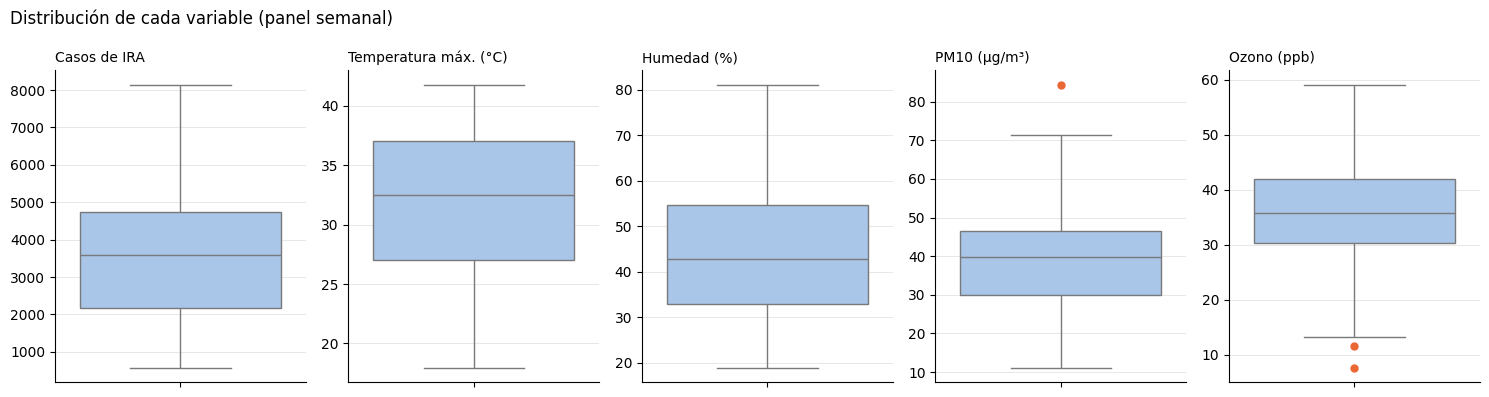

In [7]:
fig, axes = plt.subplots(1, len(VARS_CONTINUAS), figsize=(15, 4))
for ax, var in zip(axes, VARS_CONTINUAS):
    sns.boxplot(y=panel[var], ax=ax, color=AZUL_CLARO, linewidth=1,
                flierprops={"marker": "o", "markerfacecolor": NARANJA,
                            "markeredgecolor": NARANJA, "markersize": 5})
    ax.set_title(NOMBRE[var], fontsize=10, loc="left")
    ax.set_ylabel("")
fig.suptitle(f"Distribución de cada variable (panel {GRANULARIDAD})", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"outliers_boxplot_{GRANULARIDAD}.png", dpi=150)
plt.show()


**Casos por mes del año.** Muestra por qué hace falta comparar contra el mismo
mes: el pico de invierno es normal. Los puntos naranjas son las semanas de 2020,
muy por debajo de lo normal por la pandemia.

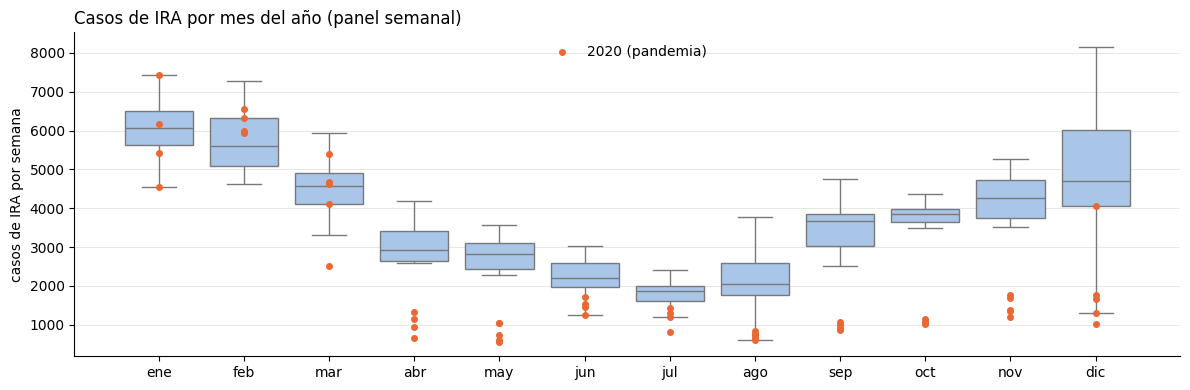

In [8]:
atipico = panel["anio_atipico"].astype(bool)

fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(x=mes, y=panel[Y], order=range(1, 13), ax=ax, color=AZUL_CLARO,
            linewidth=1, fliersize=0)
ax.scatter(mes[atipico] - 1, panel.loc[atipico, Y], color=NARANJA, s=16, zorder=3,
           label="2020 (pandemia)")
ax.set_xticks(range(12), MESES)
ax.set_xlabel("")
ax.set_ylabel("casos de IRA por semana")
ax.set_title(f"Casos de IRA por mes del año (panel {GRANULARIDAD})", loc="left")
ax.legend(loc="upper center", frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"outliers_estacionalidad_{GRANULARIDAD}.png", dpi=150)
plt.show()


**En el tiempo.** Una gráfica por variable. Naranja = atípico para todo el año
(IQR o Z-score); rombo aqua = atípico para su mes; círculo gris vacío = valor
rellenado por 3.1 (no es una medición).

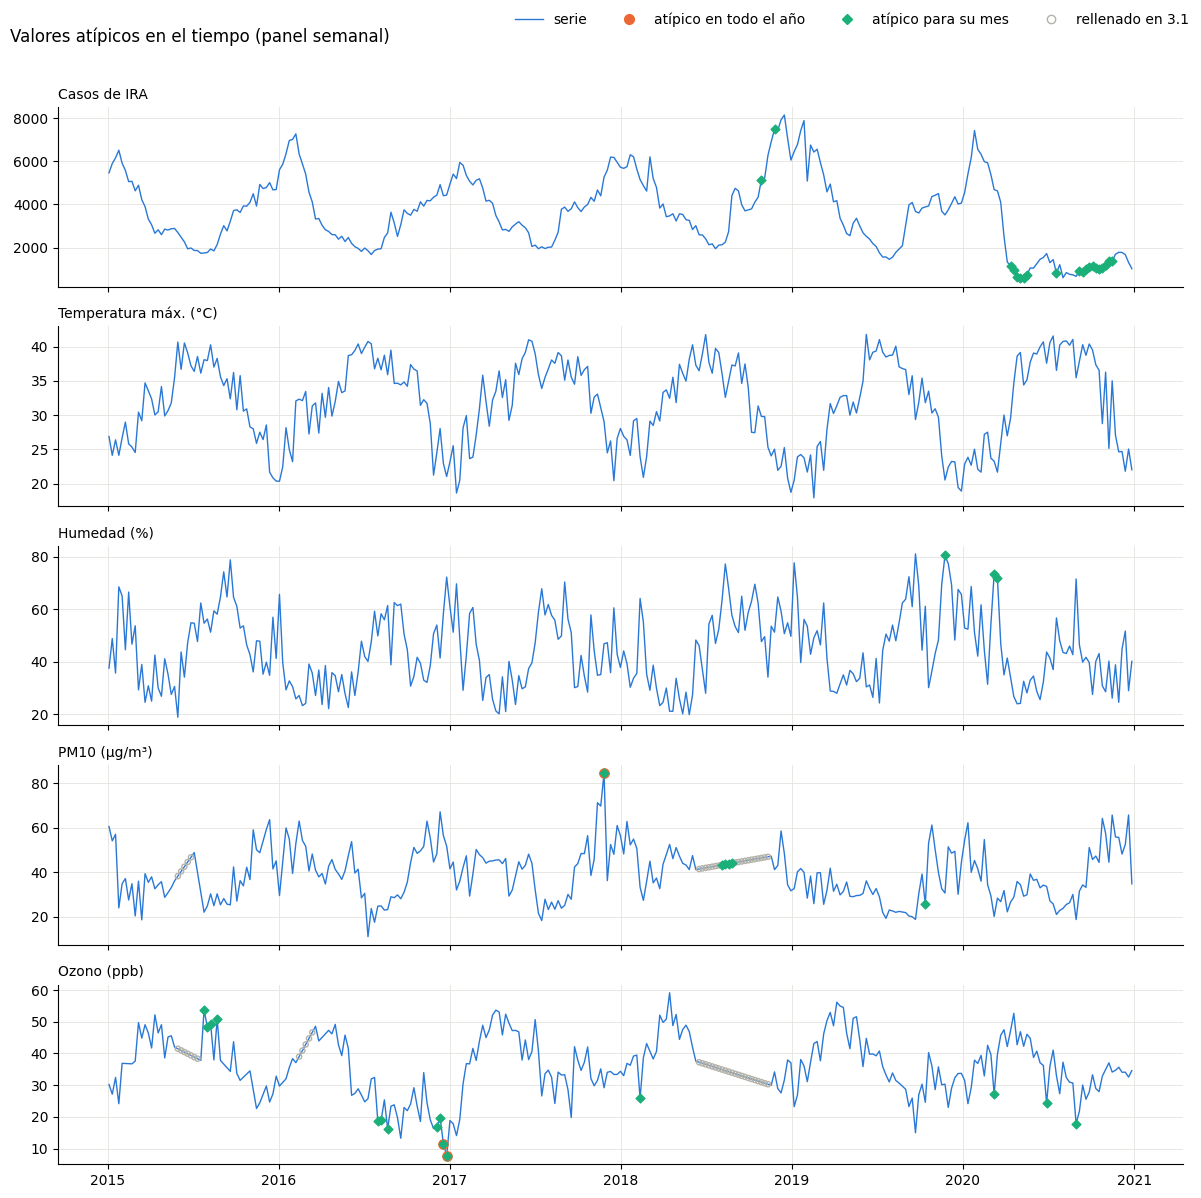

In [9]:
fig, axes = plt.subplots(len(VARS_CONTINUAS), 1, figsize=(12, 2.4 * len(VARS_CONTINUAS)),
                         sharex=True)
for ax, var in zip(axes, VARS_CONTINUAS):
    ax.plot(panel[FECHA], panel[var], color=AZUL, lw=1, zorder=1)
    rellenado = imputado[var]
    ax.scatter(panel.loc[rellenado, FECHA], panel.loc[rellenado, var], s=14,
               facecolors="none", edgecolors=GRIS_CLARO, zorder=2)
    todo_el_anio = marcas_iqr[var] | marcas_z[var]
    ax.scatter(panel.loc[todo_el_anio, FECHA], panel.loc[todo_el_anio, var], color=NARANJA,
               s=45, zorder=3)
    su_mes = marcas_estacional[var]
    ax.scatter(panel.loc[su_mes, FECHA], panel.loc[su_mes, var], color=AQUA, marker="D",
               s=20, zorder=4)
    ax.set_title(NOMBRE[var], fontsize=10, loc="left")

leyenda = [
    Line2D([], [], color=AZUL, lw=1, label="serie"),
    Line2D([], [], color=NARANJA, marker="o", lw=0, markersize=7, label="atípico en todo el año"),
    Line2D([], [], color=AQUA, marker="D", lw=0, markersize=5, label="atípico para su mes"),
    Line2D([], [], marker="o", lw=0, markerfacecolor="none", markeredgecolor=GRIS_CLARO,
           label="rellenado en 3.1"),
]
fig.legend(handles=leyenda, loc="upper right", ncol=4, frameon=False)
fig.suptitle(f"Valores atípicos en el tiempo (panel {GRANULARIDAD})", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(FIGURES_DIR / f"outliers_series_{GRANULARIDAD}.png", dpi=150)
plt.show()


## Técnica 2 — Isolation Forest (varias variables a la vez)

Busca semanas con una **combinación** rara: por ejemplo, mucho calor con mucha
humedad y pocos casos, aunque cada valor por separado sea normal. Funciona
separando las semanas con cortes al azar muchas veces: una semana rara queda
sola con muy pocos cortes, una común necesita muchos.

Antes se ponen todas las variables en la misma escala, para que ninguna pese
más solo porque sus números son más grandes (los casos van en miles y el ozono
en decenas).

In [10]:
X_esc = StandardScaler().fit_transform(panel[VARS_MULTI])

iso = IsolationForest(n_estimators=300, contamination=CONTAMINACION, random_state=SEMILLA)
iso_labels = iso.fit_predict(X_esc)  # -1 = rara, 1 = normal

panel_out = panel.copy()
panel_out["iso_outlier"] = iso_labels == -1
panel_out["iso_score"] = -iso.score_samples(X_esc)  # más alto = más rara

print(f"{PERIODOS.capitalize()} {RARAS} según Isolation Forest: "
      f"{panel_out['iso_outlier'].sum()} de {len(panel_out)}")
(panel_out.loc[panel_out["iso_outlier"], [FECHA, *VARS_MULTI, "iso_score"]]
 .sort_values("iso_score", ascending=False)
 .rename(columns={**NOMBRE, FECHA: "fecha", "iso_score": "rareza"})
 .round(2))


Semanas raras según Isolation Forest: 16 de 313


,fecha,Casos de IRA,Temperatura máx. (°C),Humedad (%),PM10 (µg/m³),Ozono (ppb),Sequía (0 a 4),rareza
171,2018-04-15,3468,32.46,21.14,52.50,59.17,4.0,0.60
295,2020-08-30,665,35.46,71.57,18.77,17.87,2.0,0.60
103,2016-12-25,4434,21.06,72.29,51.71,7.63,1.0,0.59
312,2020-12-27,1020,22.04,40.20,34.78,34.60,4.0,0.59
151,2017-11-26,5262,29.07,46.86,84.45,29.20,2.0,0.59
246,2019-09-22,3673,29.36,81.14,18.83,14.99,1.0,0.58
168,2018-03-25,3831,29.16,23.29,32.63,52.11,4.0,0.58
106,2017-01-15,5200,18.64,69.71,32.07,14.10,1.0,0.56
102,2016-12-18,4404,22.96,58.43,56.45,11.57,1.0,0.55
173,2018-04-29,3232,31.83,33.71,51.10,52.31,4.0,0.55


## Técnica 3 — Local Outlier Factor (LOF)

Para cada semana busca las 20 semanas que más se le parecen (sus "vecinas") y
compara qué tan juntas están. Si una semana queda mucho más lejos de sus vecinas
de lo que esas vecinas están entre sí, está "sola" y se marca como rara. Usa las
mismas variables en la misma escala que Isolation Forest.

In [11]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=CONTAMINACION)
lof_labels = lof.fit_predict(X_esc)  # -1 = rara, 1 = normal

# rareza LOF: ~1 = normal; más alto = más sola está la semana
panel_out["lof_outlier"] = lof_labels == -1
panel_out["lof_score"] = -lof.negative_outlier_factor_

print(f"{PERIODOS.capitalize()} {RARAS} según LOF: "
      f"{panel_out['lof_outlier'].sum()} de {len(panel_out)}")
(panel_out.loc[panel_out["lof_outlier"], [FECHA, *VARS_MULTI, "lof_score"]]
 .sort_values("lof_score", ascending=False)
 .rename(columns={**NOMBRE, FECHA: "fecha", "lof_score": "rareza"})
 .round(2))


Semanas raras según LOF: 16 de 313


,fecha,Casos de IRA,Temperatura máx. (°C),Humedad (%),PM10 (µg/m³),Ozono (ppb),Sequía (0 a 4),rareza
151,2017-11-26,5262,29.07,46.86,84.45,29.20,2.0,1.54
103,2016-12-25,4434,21.06,72.29,51.71,7.63,1.0,1.42
312,2020-12-27,1020,22.04,40.20,34.78,34.60,4.0,1.39
171,2018-04-15,3468,32.46,21.14,52.50,59.17,4.0,1.38
295,2020-08-30,665,35.46,71.57,18.77,17.87,2.0,1.35
29,2015-07-26,1748,38.09,54.71,22.07,53.76,0.0,1.35
310,2020-12-13,1669,21.81,51.71,52.48,34.11,3.0,1.34
308,2020-11-29,1779,24.66,24.57,55.65,35.67,3.0,1.33
163,2018-02-18,4873,20.93,55.14,27.39,38.68,3.0,1.32
162,2018-02-11,5152,23.94,64.14,33.29,25.83,3.0,1.31


## Comparación de técnicas

Una semana que marcan varias técnicas es más confiable que una que marca solo
una. La tabla dice **cuántas semanas marcan a la vez cada par de técnicas**; la
diagonal es el total de cada una.

In [12]:
# una columna por técnica; en las reglas de una variable basta con que UNA variable sea atípica
tecnicas = pd.DataFrame({
    "IQR": marcas_iqr.any(axis=1),
    "Z-score": marcas_z.any(axis=1),
    "Contra su mes": marcas_estacional.any(axis=1),
    "Isolation Forest": panel_out["iso_outlier"],
    "LOF": panel_out["lof_outlier"],
})
panel_out["n_tecnicas"] = tecnicas.sum(axis=1)

# coincidencias: para cada par de técnicas, en cuántos periodos marcaron las dos
t = tecnicas.astype(int)
t.T @ t


,IQR,Z-score,Contra su mes,Isolation Forest,LOF
IQR,3,2,3,3,2
Z-score,2,2,2,2,2
Contra su mes,3,2,43,5,8
Isolation Forest,3,2,5,16,7
LOF,2,2,8,7,16


**Calendario de semanas raras.** Una fila por año y una columna por semana; el
color dice cuántas de las 5 técnicas marcaron esa semana (blanco = ninguna,
más oscuro = más técnicas coinciden). Sirve para ver de un vistazo si las
semanas raras se juntan en ciertas épocas o años.

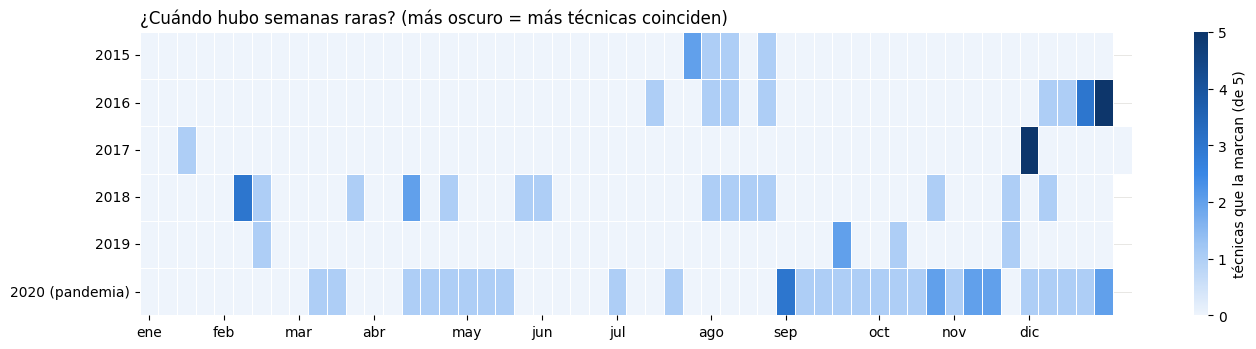

In [13]:
if GRANULARIDAD == "semanal":
    posicion = (panel_out[FECHA].dt.dayofyear - 1) // 7 + 1  # semana del año, 1-53
    columnas = range(1, 54)
else:
    posicion = panel_out[FECHA].dt.month
    columnas = range(1, 13)

calendario = (panel_out.assign(anio=panel_out[FECHA].dt.year, posicion=posicion)
              .pivot_table(index="anio", columns="posicion", values="n_tecnicas", aggfunc="max")
              .reindex(columns=columnas))

fig, ax = plt.subplots(figsize=(14, 3.6))
sns.heatmap(calendario, cmap=AZULES, vmin=0, vmax=5, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "técnicas que la marcan (de 5)", "ticks": range(6)}, ax=ax)
if GRANULARIDAD == "semanal":
    inicio_mes = pd.date_range("2019-01-01", periods=12, freq="MS").dayofyear
    ax.set_xticks([(d - 1) // 7 + 0.5 for d in inicio_mes], MESES, rotation=0)
else:
    ax.set_xticks(np.arange(12) + 0.5, MESES, rotation=0)
anio_pandemia = panel_out.groupby(panel_out[FECHA].dt.year)["anio_atipico"].mean() > 0.5
ax.set_yticklabels([f"{a} (pandemia)" if anio_pandemia.get(a, False) else str(a)
                    for a in calendario.index], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(f"¿Cuándo hubo {PERIODOS} {RARAS}? (más oscuro = más técnicas coinciden)", loc="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"outliers_calendario_{GRANULARIDAD}.png", dpi=150)
plt.show()


**Las semanas en las que coinciden Isolation Forest y LOF.** Son las más
confiables. Para cada una se indica qué variable estuvo más fuera de lo normal
**para su mes**, que es la que mejor explica por qué la semana es rara.

In [14]:
panel_out["outlier_consenso"] = panel_out["iso_outlier"] & panel_out["lof_outlier"]

# variable más fuera de lo normal para su mes: la de mayor distancia (en "pasos")
z_mes = pd.DataFrame({v: z_estacional(panel[v], mes) for v in VARS_MULTI})
panel_out["variable_mas_extrema"] = z_mes.abs().idxmax(axis=1)
panel_out["z_estacional"] = [z_mes.at[i, v] for i, v in panel_out["variable_mas_extrema"].items()]

consenso = panel_out.loc[panel_out["outlier_consenso"], [FECHA, *VARS_MULTI]].copy()
consenso["variable más rara para su mes"] = panel_out.loc[
    panel_out["outlier_consenso"], "variable_mas_extrema"].map(NOMBRE)
consenso["técnicas que la marcan"] = panel_out.loc[panel_out["outlier_consenso"], "n_tecnicas"]
consenso["2020"] = np.where(panel_out.loc[panel_out["outlier_consenso"], "anio_atipico"].astype(bool), "sí", "no")
consenso.rename(columns={**NOMBRE, FECHA: "fecha"}).round(1)


,fecha,Casos de IRA,Temperatura máx. (°C),Humedad (%),PM10 (µg/m³),Ozono (ppb),Sequía (0 a 4),variable más rara para su mes,técnicas que la marcan,2020
103,2016-12-25,4434,21.1,72.3,51.7,7.6,1.0,Ozono (ppb),5,no
151,2017-11-26,5262,29.1,46.9,84.4,29.2,2.0,PM10 (µg/m³),5,no
162,2018-02-11,5152,23.9,64.1,33.3,25.8,3.0,Ozono (ppb),3,no
171,2018-04-15,3468,32.5,21.1,52.5,59.2,4.0,Ozono (ppb),2,no
246,2019-09-22,3673,29.4,81.1,18.8,15.0,1.0,Temperatura máx. (°C),2,no
295,2020-08-30,665,35.5,71.6,18.8,17.9,2.0,Ozono (ppb),3,sí
312,2020-12-27,1020,22.0,40.2,34.8,34.6,4.0,Casos de IRA,2,sí


**Las dos técnicas, cara a cara.** Cada punto es una semana: más a la derecha =
más rara para Isolation Forest; más arriba = más rara para LOF. Las que quedan
arriba a la derecha son raras para las dos y llevan su fecha.

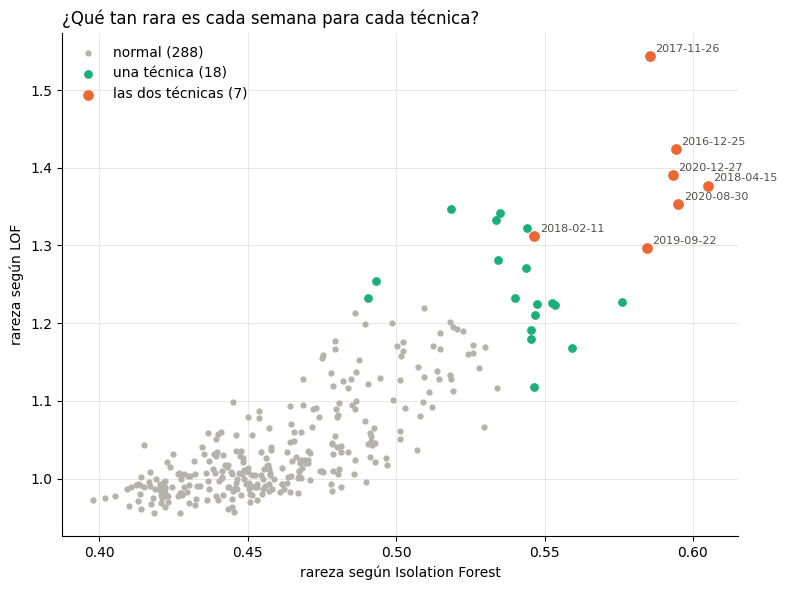

In [15]:
categoria = np.select(
    [panel_out["outlier_consenso"], panel_out["iso_outlier"] | panel_out["lof_outlier"]],
    ["las dos técnicas", "una técnica"],
    default="normal",
)

fig, ax = plt.subplots(figsize=(8, 6))
for etiqueta, color, tamano in [("normal", GRIS_CLARO, 12), ("una técnica", AQUA, 28),
                                ("las dos técnicas", NARANJA, 45)]:
    m = categoria == etiqueta
    ax.scatter(panel_out.loc[m, "iso_score"], panel_out.loc[m, "lof_score"], color=color,
               s=tamano, label=f"{etiqueta} ({m.sum()})")
for _, fila in panel_out[panel_out["outlier_consenso"]].iterrows():
    ax.annotate(f"{fila[FECHA]:%Y-%m-%d}", (fila["iso_score"], fila["lof_score"]),
                xytext=(4, 3), textcoords="offset points", fontsize=8, color=GRIS)
ax.set_xlabel("rareza según Isolation Forest")
ax.set_ylabel("rareza según LOF")
ax.set_title(f"¿Qué tan rara es cada {'semana' if GRANULARIDAD == 'semanal' else 'mes'} "
             "para cada técnica?", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"outliers_score_scatter_{GRANULARIDAD}.png", dpi=150)
plt.show()


**Sobre la serie de casos.** Las semanas raras marcadas encima de los casos de
IRA. El fondo gris es 2020.

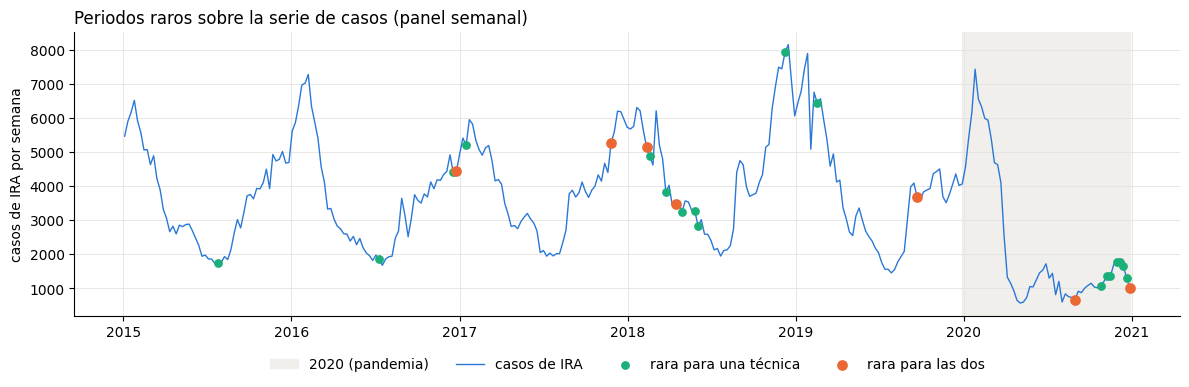

In [16]:
alguna = panel_out["iso_outlier"] | panel_out["lof_outlier"]
una_sola = alguna & ~panel_out["outlier_consenso"]
ambas = panel_out["outlier_consenso"]

fig, ax = plt.subplots(figsize=(12, 4))
if atipico.any():
    ax.axvspan(panel_out.loc[atipico, FECHA].min(), panel_out.loc[atipico, FECHA].max(),
               color=FONDO_2020, zorder=0, label="2020 (pandemia)")
ax.plot(panel_out[FECHA], panel_out[Y], color=AZUL, lw=1, zorder=1, label="casos de IRA")
ax.scatter(panel_out.loc[una_sola, FECHA], panel_out.loc[una_sola, Y], color=AQUA, s=28,
           zorder=2, label="rara para una técnica")
ax.scatter(panel_out.loc[ambas, FECHA], panel_out.loc[ambas, Y], color=NARANJA, s=45,
           zorder=3, label="rara para las dos")
ax.set_ylabel("casos de IRA por semana")
ax.set_title(f"Periodos raros sobre la serie de casos (panel {GRANULARIDAD})", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"outliers_multivariado_series_{GRANULARIDAD}.png", dpi=150)
plt.show()


## Qué encontramos

Resultados del **panel semanal** (313 semanas):

| Técnica | Semanas que marca | Qué encuentra |
|---------|-------------------|---------------|
| IQR | 3 | Ozono muy bajo (18 y 25 de diciembre de 2016) y el PM10 más alto del periodo (26 de noviembre de 2017) |
| Z-score | 2 | Las dos más extremas de las anteriores |
| Contra su mes | 43 | Las semanas de 2020 con pocos casos, el inicio adelantado de la temporada de IRA de 2018, ozono fuera de lo normal, semanas muy húmedas y 4 semanas de PM10 que en realidad rellenó 3.1 |
| Isolation Forest | 16 (5 %) | Combinaciones raras: la primavera seca de 2018 con mucho ozono, episodios de aire y humedad, semanas de 2020 |
| LOF | 16 (5 %) | Sobre todo el final de 2020: pocos casos con sequía, algo que no pasó en ningún otro año |

Isolation Forest y LOF coinciden en **7 semanas**: son las más confiables.

**¿Por qué las reglas clásicas casi no encuentran nada?** Al juntar los datos
por semana, los picos de un solo día se suavizan. Y cada variable cambia mucho
con la época del año: el pico de casos de invierno (hasta 8,148 por semana) no
es raro, es la temporada. Por eso sirve más comparar con lo normal para cada mes
o mirar varias variables a la vez.

### ¿Error o evento real?

| Periodo | Qué pasó | ¿Qué es? | ¿Qué se hace? |
|---------|----------|----------|---------------|
| 2020 (abr–may y sep–dic) | Muchos menos casos de lo normal (hasta 569 por semana) | La pandemia cambió el registro de casos, no la enfermedad | Se conserva; ya tiene su marca `anio_atipico` (3.0) |
| 26-nov-2017 | El PM10 más alto del periodo (84 µg/m³); siguió alto más de una semana | Episodio real de contaminación | Se conserva |
| 15-abr-2018 (y la primavera de 2018) | El ozono más alto (59 ppb), aire muy seco y sequía extrema | Evento real: una primavera muy seca | Se conserva |
| 22-sep-2019 | La semana más húmeda del periodo (81 %), con menos calor | Evento real (muy probablemente lluvias) | Se conserva |
| Oct–nov 2018 | Más casos de lo normal para esos meses (hasta 7,488 por semana) | La temporada de IRA empezó antes | Se conserva |
| Dic-2016 y feb-2018 (también el verano de 2016) | Ozono muy bajo: 7.6 y 11.6 ppb, cuando lo normal en diciembre es ~31 | **Dudoso:** puede ser real o una falla del sensor, y la estación lo marca como dato confiable | Se conserva con su marca; revisar si los resultados con ozono cambian sin esas semanas |
| Jun–nov 2018 (PM10 y ozono) | La estación estuvo apagada y 3.1 rellenó el hueco con una línea recta | No es una medición, es un valor estimado | Se conserva; en 3.3–3.4 repetir lo del aire sin esas semanas |

**En el panel mensual** salen los mismos episodios: las reglas clásicas no
marcan ningún mes, la comparación contra su mes marca 17, y las dos técnicas de
varias variables coinciden en diciembre de 2016, abril de 2018 y diciembre de 2020.

## Decisiones

| Decisión | Panel | Por qué | Fecha |
| :--- | :--- | :--- | :--- |
| **No borrar ni corregir ningún dato** | Ambos | La mayoría de las semanas raras son eventos reales (contaminación, calor, sequía, lluvias), que es justo lo que se quiere estudiar. Para el ozono dudoso no hay pruebas suficientes de que sea un error | Nov 2026 |
| **Pedir a Isolation Forest y LOF el mismo 5 %** | Ambos | Sin eso, una marcaba cerca del 20 % de las semanas y la otra menos del 1 %, y no se podían comparar | Nov 2026 |
| **Agregar la comparación contra su mes** | Ambos | Las reglas clásicas no ven nada raro en variables con una temporada tan marcada | Nov 2026 |
| **No aplicar las reglas de una variable a olas de calor, sequía ni marginación** | Ambos | Las olas de calor casi siempre valen 0, la sequía es una escala de 0 a 4 y la marginación es una línea recta | Nov 2026 |
| **Guardar las marcas en `panel_eda_outliers_{GRANULARIDAD}.parquet`** | Ambos | Para repetir análisis sin las semanas raras y ver si los resultados cambian | Nov 2026 |

In [17]:
# una columna True/False por técnica, sin borrar valores:
# 3.4 y 3.5 pueden repetir el análisis sin esos periodos
salida = panel.assign(
    outlier_iqr=tecnicas["IQR"],
    outlier_zscore=tecnicas["Z-score"],
    outlier_estacional=tecnicas["Contra su mes"],
    outlier_iforest=panel_out["iso_outlier"],
    iforest_score=panel_out["iso_score"],
    outlier_lof=panel_out["lof_outlier"],
    lof_score=panel_out["lof_score"],
    n_tecnicas=panel_out["n_tecnicas"],
    outlier_consenso=panel_out["outlier_consenso"],
)
ruta_salida = PROCESSED_DATA_DIR / f"panel_eda_outliers_{GRANULARIDAD}.parquet"
salida.to_parquet(ruta_salida, index=False)
print(f"✓ Guardado: {ruta_salida.name} ({len(salida)} {PERIODOS}, {salida.shape[1]} columnas)")
print(f"  {PERIODOS.capitalize()} {RARAS} para las dos técnicas: {int(salida['outlier_consenso'].sum())}")


✓ Guardado: panel_eda_outliers_semanal.parquet (313 semanas, 20 columnas)
  Semanas raras para las dos técnicas: 7


## Consulta con el equipo (checkpoint 1)

Registrar aquí lo que se presentó al equipo sobre los outliers detectados y qué se decidió
(ver `docs/docs/protocolo_eda.md`, sección 5.3).

| Fecha | Participantes | Hallazgo o pregunta presentada | Decisión |
|-------|---------------|-------------------------------|----------|
| Nov 2026 | Patricia Quiroz | Se presentó la comparación de las cuatro técnicas (IQR, Z-score, comparación contra lo normal de cada mes, Isolation Forest y LOF). IF y LOF coinciden en 7 semanas raras; casi todas son eventos reales (episodio de PM10 de nov-2017, primavera seca de 2018, semanas de 2020 por la pandemia) salvo el ozono muy bajo de dic-2016, que parece un posible error del sensor. | **No se borra ni se corrige ningún dato.** Se guardan las marcas por técnica en `panel_eda_outliers_*.parquet` para poder repetir los análisis sin las semanas raras. El ozono de dic-2016 queda marcado como dudoso: en 3.4 se revisan las correlaciones con y sin 2016. |